# Assignment 2 — Nhiệm vụ A (Chương 6): phân phối rời rạc và bảng đồng thời
**Dữ liệu:** UCI *Seeds* (ID 236): N = 210 mẫu, 7 đặc trưng số thực (Area, Perimeter, Compactness, Kernel_Length, Kernel_Width, Asymmetry, Groove_Length) và nhãn giống (3 giống, mỗi giống 70 mẫu). Phần A không dùng nhãn.

**Cách chạy:** đặt file `seeds_dataset.txt` (lấy từ `seeds.zip` của UCI) cùng thư mục với notebook. Nếu không có file, notebook thử `ucimlrepo` (`pip install ucimlrepo`).

Mỗi mục trình bày theo: **đề bài → lời giải → nhận xét**. Các ô *nhận xét* để nhóm điền sau khi xem số liệu thật.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

COLS = ["Area","Perimeter","Compactness","Kernel_Length","Kernel_Width","Asymmetry","Groove_Length","Class"]
FEAT = COLS[:7]

def load_seeds():
    p = Path("seeds_dataset.txt")
    if p.exists():
        return pd.read_csv(p, sep=r"\s+", header=None, names=COLS)
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=236)
    d = ds.data.features.copy()
    d.columns = FEAT
    d["Class"] = ds.data.targets.iloc[:, 0].values
    return d

df = load_seeds()
assert df.shape == (210, 8), df.shape
assert df.isna().sum().sum() == 0
N = len(df)
print("N =", N)
df.head()

N = 210


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


## Bước 0 — Chọn cặp (X, Y)
Đề yêu cầu chọn hai đặc trưng có tương quan rõ rệt, nên vẽ tán xạ trước. **Cặp này phải trùng với cặp nhóm dùng ở Nhiệm vụ B.**
Ô dưới liệt kê ma trận tương quan và gợi ý một cặp; nhóm có thể ghi đè bằng biến `PAIR`.

                Area  Perimeter  Compactness  Kernel_Length  Kernel_Width  \
Area           1.000      0.994        0.608          0.950         0.971   
Perimeter      0.994      1.000        0.529          0.972         0.945   
Compactness    0.608      0.529        1.000          0.368         0.762   
Kernel_Length  0.950      0.972        0.368          1.000         0.860   
Kernel_Width   0.971      0.945        0.762          0.860         1.000   
Asymmetry     -0.230     -0.217       -0.331         -0.172        -0.258   
Groove_Length  0.864      0.891        0.227          0.933         0.749   

               Asymmetry  Groove_Length  
Area              -0.230          0.864  
Perimeter         -0.217          0.891  
Compactness       -0.331          0.227  
Kernel_Length     -0.172          0.933  
Kernel_Width      -0.258          0.749  
Asymmetry          1.000         -0.011  
Groove_Length     -0.011          1.000  
Cặp được chọn: X = Compactness , Y = Kernel_Wid

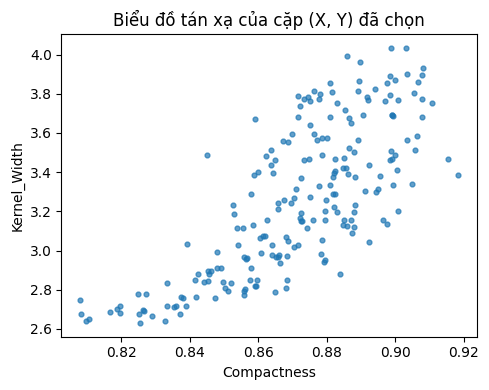

In [3]:
corr = df[FEAT].corr()
print(corr.round(3))

PAIR = ("Compactness", "Kernel_Width")           # ví dụ: ("Area", "Asymmetry"). None = để code gợi ý
if PAIR is None:
    cand = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEAT) for b in FEAT[i+1:] if abs(corr.loc[a, b]) < 0.95]
    PAIR = min(cand, key=lambda t: abs(abs(t[2]) - 0.8))[:2]   # tương quan rõ nhưng không gần như tuyến tính hoàn hảo
XN, YN = PAIR
print("Cặp được chọn: X =", XN, ", Y =", YN, ", r =", round(corr.loc[XN, YN], 4))

plt.figure(figsize=(5, 4))
plt.scatter(df[XN], df[YN], s=12, alpha=.7)
plt.xlabel(XN); plt.ylabel(YN); plt.title("Biểu đồ tán xạ của cặp (X, Y) đã chọn")
plt.tight_layout(); plt.show()

## A1 — Rời rạc hoá và phân phối đồng thời thực nghiệm
**Đề bài.** Rời rạc hoá X, Y thành 3 mức (thấp/trung bình/cao) bằng phân vị 33% và 67%; lập bảng tần suất 3×3; chia cho N để được $p(x,y)$; kiểm tra tổng bằng 1.

**Lời giải.** Hai ngưỡng $q_{33}, q_{67}$ của mỗi đặc trưng chia dữ liệu thành: thấp ($\le q_{33}$), trung bình ($q_{33}<\cdot\le q_{67}$), cao ($>q_{67}$). Gọi $n_{xy}$ là số mẫu rơi vào ô $(x,y)$, thì
$$p(x,y)=\frac{n_{xy}}{N},\qquad \sum_{x,y}p(x,y)=\frac{1}{N}\sum_{x,y}n_{xy}=\frac{N}{N}=1,$$
vì mỗi mẫu rơi đúng vào một ô.

In [4]:
LV = ["thấp", "trung bình", "cao"]
Q = [0, 0.33, 0.67, 1]
df["X_lvl"] = pd.qcut(df[XN], q=Q, labels=LV)
df["Y_lvl"] = pd.qcut(df[YN], q=Q, labels=LV)
print("Ngưỡng X (q33, q67):", np.quantile(df[XN], [0.33, 0.67]).round(4))
print("Ngưỡng Y (q33, q67):", np.quantile(df[YN], [0.33, 0.67]).round(4))

counts = pd.crosstab(df["X_lvl"], df["Y_lvl"]).reindex(index=LV, columns=LV, fill_value=0)
print("\nBảng tần suất n_xy (hàng = X, cột = Y):")
print(counts)
assert counts.values.sum() == N

p = counts / N
print("\nBảng p(x,y) = n_xy / N:")
print(p.round(4))
print("\nTổng các ô p(x,y) =", p.values.sum())
assert abs(p.values.sum() - 1) < 1e-12

Ngưỡng X (q33, q67): [0.8637 0.8829]
Ngưỡng Y (q33, q67): [3.0318 3.464 ]

Bảng tần suất n_xy (hàng = X, cột = Y):
Y_lvl       thấp  trung bình  cao
X_lvl                            
thấp          53          13    3
trung bình    15          32   25
cao            1          27   41

Bảng p(x,y) = n_xy / N:
Y_lvl         thấp  trung bình     cao
X_lvl                                 
thấp        0.2524      0.0619  0.0143
trung bình  0.0714      0.1524  0.1190
cao         0.0048      0.1286  0.1952

Tổng các ô p(x,y) = 0.9999999999999999


**Nhận xét A1: Hai ngưỡng phân vị chia mỗi đặc trưng thành ba mức với số mẫu 69 / 72 / 69, gần 1/3 của N = 210 (không đúng 70 vì 33% và 67% không bằng đúng 1/3 và 2/3). Tổng các ô p(x,y) bằng 1 (máy in 0.9999999999999999 do sai số làm tròn số thực). Bảng không đều: ba ô trên đường chéo (53, 32, 41) chiếm 126/210 = 60% số mẫu, trong khi hai ô góc đối diện rất thưa, (X thấp, Y cao) chỉ có 3 mẫu và (X cao, Y thấp) chỉ có 1 mẫu. Nếu X và Y độc lập thì mỗi ô góc kỳ vọng khoảng 69×69/210 ≈ 22.7 mẫu; ô (thấp, thấp) có 53 mẫu, gấp hơn hai lần mức đó, còn hai ô góc kia thấp hơn nhiều. Điều này gợi ý Compactness và Kernel_Width phụ thuộc cùng chiều: giá trị này thấp thì giá trị kia thường thấp, và ngược lại. Kết luận chặt chẽ sẽ được kiểm tra ở A4.

## A2 — Phân phối biên và phân phối có điều kiện
**Đề bài.** Ghi phân phối biên $p_X, p_Y$ ra lề bảng; tính $p(y\mid x)$ cho một hàng cụ thể và $p(x\mid y)$ cho một cột cụ thể; chỉ rõ hai kết quả khác nhau và giải thích.

**Lời giải.**
$$p_X(x)=\sum_y p(x,y)\ (\text{tổng hàng}),\qquad p_Y(y)=\sum_x p(x,y)\ (\text{tổng cột}),$$
$$p(y\mid x)=\frac{p(x,y)}{p_X(x)}\ (\text{chia cho tổng hàng}),\qquad p(x\mid y)=\frac{p(x,y)}{p_Y(y)}\ (\text{chia cho tổng cột}).$$
Hai đại lượng có cùng tử số $p(x,y)$ nhưng **mẫu số khác nhau** ($p_X(x)$ so với $p_Y(y)$), nên nói chung khác nhau; chúng chỉ liên hệ với nhau qua công thức Bayes $p(x\mid y)=p(y\mid x)\,p_X(x)/p_Y(y)$. Mỗi dòng $p(y\mid x)$ cộng lại bằng 1 (cộng theo $y$), mỗi cột $p(x\mid y)$ cộng lại bằng 1 (cộng theo $x$); *không* có tính chất cộng bằng 1 theo chiều còn lại.

**Lưu ý khi đọc số:** vì X và Y được chia theo phân vị 33%/67%, các lề ,p_Y$ đều xấp xỉ 1/3, nên ở *một ô chung* hai xác suất có điều kiện có thể gần bằng nhau về số. Sự khác nhau thể hiện rõ khi so sánh **cả dãy**: (y\mid x=x_0)$ là phân phối trên $ (chia theo hàng), còn (x\mid y=y_0)$ là phân phối trên $ (chia theo cột); hai dãy này khác nhau khi bảng không đối xứng.

In [6]:
P = p.values                      # hàng = X, cột = Y
pX = P.sum(axis=1)                # tổng hàng
pY = P.sum(axis=0)                # tổng cột

table = p.copy()
table["p_X (lề)"] = pX
table.loc["p_Y (lề)"] = list(pY) + [pX.sum()]
print("Bảng p(x,y) kèm hai lề:")
print(table.round(4))

# --- Chọn một hàng (X = x0) và một cột (Y = y0) cụ thể ---
x0, y0 = "trung bình", "cao"         # hàng X = thấp, cột Y = cao; nhóm có thể đổi
i0, j0 = LV.index(x0), LV.index(y0)

p_y_given_x = P[i0, :] / pX[i0]
p_x_given_y = P[:, j0] / pY[j0]
print(f"\np(y | x = {x0}) =", {k: round(float(v), 4) for k, v in zip(LV, p_y_given_x)}, "; tổng =", p_y_given_x.sum().round(6))
print(f"p(x | y = {y0}) =", {k: round(float(v), 4) for k, v in zip(LV, p_x_given_y)}, "; tổng =", p_x_given_y.sum().round(6))

# Hai kết quả khác nhau ở ô chung (x0, y0): cùng tử số, khác mẫu số
print(f"\nÔ chung: p({x0},{y0}) = {P[i0, j0]:.4f}")
print(f"  p(y={y0} | x={x0}) = {P[i0, j0]:.4f} / {pX[i0]:.4f} = {p_y_given_x[j0]:.4f}")
print(f"  p(x={x0} | y={y0}) = {P[i0, j0]:.4f} / {pY[j0]:.4f} = {p_x_given_y[i0]:.4f}")

# Kiểm tra Bayes
bayes = p_y_given_x[j0] * pX[i0] / pY[j0]
print(f"  Bayes: p(y|x) p(x) / p(y) = {bayes:.4f}  (phải bằng p(x|y))")
assert abs(bayes - p_x_given_y[i0]) < 1e-12

Bảng p(x,y) kèm hai lề:
Y_lvl         thấp  trung bình     cao  p_X (lề)
X_lvl                                           
thấp        0.2524      0.0619  0.0143    0.3286
trung bình  0.0714      0.1524  0.1190    0.3429
cao         0.0048      0.1286  0.1952    0.3286
p_Y (lề)    0.3286      0.3429  0.3286    1.0000

p(y | x = trung bình) = {'thấp': 0.2083, 'trung bình': 0.4444, 'cao': 0.3472} ; tổng = 1.0
p(x | y = cao) = {'thấp': 0.0435, 'trung bình': 0.3623, 'cao': 0.5942} ; tổng = 1.0

Ô chung: p(trung bình,cao) = 0.1190
  p(y=cao | x=trung bình) = 0.1190 / 0.3429 = 0.3472
  p(x=trung bình | y=cao) = 0.1190 / 0.3286 = 0.3623
  Bayes: p(y|x) p(x) / p(y) = 0.3623  (phải bằng p(x|y))


**Nhận xét A2: Hai lề p_X và p_Y gần bằng nhau (0.3286, 0.3429, 0.3286) vì cả hai biến đều được chia theo cùng cặp phân vị. Ở ô chung (trung bình, cao), cùng tử số p(x,y) = 0.1190 nhưng p(y = cao ∣ x = trung bình) = 0.1190/0.3429 = 0.3472 còn p(x = trung bình ∣ y = cao) = 0.1190/0.3286 = 0.3623. Hai kết quả khác nhau vì mẫu số khác nhau: p(y∣x) chia cho tổng hàng, còn p(x∣y) chia cho tổng cột. Hai đại lượng chỉ liên hệ với nhau qua công thức Bayes p(x∣y) = p(y∣x)·p_X(x)/p_Y(y), và đã kiểm tra khớp bằng số. Ở ví dụ thứ hai, ô (thấp, cao), hai giá trị trùng số (0.0435) chỉ vì p_X(thấp) = p_Y(cao) = 69/210, không phải hai đại lượng bằng nhau về bản chất. Về ý nghĩa, xác suất không điều kiện P(Y thấp) = 0.3286, nhưng khi biết X thấp thì P(Y thấp ∣ X thấp) = 0.7681, tăng hơn gấp đôi; tương tự P(X cao ∣ Y cao) = 0.5942 so với 0.3286. Biết giá trị của một biến làm phân phối của biến kia thay đổi, nghĩa là X và Y không độc lập.

## A3 — Kỳ vọng, hiệp phương sai và hệ số tương quan từ bảng
**Đề bài.** Tính $E[X],E[Y],E[XY],\mathrm{Cov}[X,Y],\mathrm{corr}[X,Y]$ từ bảng; **làm tay ít nhất phép tính Cov**, trình bày đủ các bước.

**Quy ước.** Gán số cho ba mức: thấp = 1, trung bình = 2, cao = 3. Đây là một lựa chọn, nếu đổi cách gán thì $E$ và Cov đổi theo, nên phải ghi rõ trong báo cáo.

**Công thức.**
$$E[X]=\sum_x x\,p_X(x),\quad E[Y]=\sum_y y\,p_Y(y),\quad E[XY]=\sum_{x,y}xy\,p(x,y),$$
$$\mathrm{Cov}[X,Y]=E[XY]-E[X]E[Y],\quad V[X]=E[X^2]-E[X]^2,\quad \mathrm{corr}[X,Y]=\frac{\mathrm{Cov}[X,Y]}{\sqrt{V[X]\,V[Y]}}.$$

**Năm bước làm tay (theo đúng hướng dẫn của đề):** (1) tổng hàng, (2) tổng cột, (3) $E[X]$ và $E[Y]$, (4) $E[XY]$ từng ô, (5) thay vào công thức Cov. Ô code dưới in ra từng con số của năm bước để nhóm **chép bảng ra giấy, tự tính và đối chiếu**. Phần làm tay bắt buộc tự làm, không chép lại output của code.

In [7]:
xs = np.array([1, 2, 3]); ys = np.array([1, 2, 3])

print("Bước 1 — tổng hàng p_X =", pX.round(4))
print("Bước 2 — tổng cột p_Y =", pY.round(4))

EX = float((xs * pX).sum()); EY = float((ys * pY).sum())
print(f"Bước 3 — E[X] = {EX:.4f},  E[Y] = {EY:.4f}")

xyp = np.outer(xs, ys) * P        # ô (i,j) = x*y*p(x,y)
print("Bước 4 — bảng x*y*p(x,y) từng ô:")
print(pd.DataFrame(xyp, index=LV, columns=LV).round(4))
EXY = float(xyp.sum())
print(f"         E[XY] = tổng các ô = {EXY:.4f}")

cov = EXY - EX * EY
print(f"Bước 5 — Cov[X,Y] = E[XY] - E[X]E[Y] = {EXY:.4f} - {EX:.4f}*{EY:.4f} = {cov:.4f}")

VX = float((xs**2 * pX).sum() - EX**2); VY = float((ys**2 * pY).sum() - EY**2)
corr_xy = cov / np.sqrt(VX * VY)
print(f"V[X] = {VX:.4f},  V[Y] = {VY:.4f},  corr[X,Y] = {corr_xy:.4f}")

# Kiểm tra chéo bằng numpy trên mã mức (mẫu số N, khớp quy ước của môn học)
cx = df["X_lvl"].map(dict(zip(LV, xs))).astype(float).values
cy = df["Y_lvl"].map(dict(zip(LV, ys))).astype(float).values
cov_np = np.cov(cx, cy, bias=True)[0, 1]
print(f"Kiểm tra: np.cov(bias=True) = {cov_np:.4f}")
assert abs(cov - cov_np) < 1e-10
assert abs(corr_xy - np.corrcoef(cx, cy)[0, 1]) < 1e-10

Bước 1 — tổng hàng p_X = [0.3286 0.3429 0.3286]
Bước 2 — tổng cột p_Y = [0.3286 0.3429 0.3286]
Bước 3 — E[X] = 2.0000,  E[Y] = 2.0000
Bước 4 — bảng x*y*p(x,y) từng ô:
              thấp  trung bình     cao
thấp        0.2524      0.1238  0.0429
trung bình  0.1429      0.6095  0.7143
cao         0.0143      0.7714  1.7571
         E[XY] = tổng các ô = 4.4286
Bước 5 — Cov[X,Y] = E[XY] - E[X]E[Y] = 4.4286 - 2.0000*2.0000 = 0.4286
V[X] = 0.6571,  V[Y] = 0.6571,  corr[X,Y] = 0.6522
Kiểm tra: np.cov(bias=True) = 0.4286


**Nhận xét A3: 
•Cov > 0 và corr ≈ 0.65: X và Y biến thiên cùng chiều ở mức khá mạnh, phù hợp nhận xét ở A1 (các ô trên đường chéo dày hơn).
•E[X] = E[Y] = 2 là hệ quả của hai lề giống hệt nhau (69, 72, 69) và cùng cách gán 1, 2, 3.
•corr = 0.6522 khác r = 0.7616 ở bước chọn cặp. Hai số không mâu thuẫn: 0.7616 tính trên dữ liệu liên tục, còn 0.6522 tính trên biến đã rời rạc hoá thành 3 mức gán 1, 2, 3 nên mất bớt thông tin và phụ thuộc cách gán.

## A4 — Kiểm tra tính độc lập
**Đề bài.** Nêu điều kiện cần kiểm tra, chỉ ra ít nhất một ô vi phạm (hoặc chứng minh mọi ô đều thoả). Nếu tìm được Cov gần 0 mà hai biến vẫn phụ thuộc, nêu rõ và giải thích.

**Lời giải.** $X$ và $Y$ độc lập khi và chỉ khi
$$p(x,y)=p_X(x)\,p_Y(y)\quad\text{với mọi } (x,y)\in\{1,2,3\}^2\ (\text{cả 9 ô}).$$
Chỉ cần **một ô** không thoả là kết luận phụ thuộc. Quan hệ với Cov: độc lập $\Rightarrow E[XY]=E[X]E[Y]\Rightarrow \mathrm{Cov}=0$; chiều ngược lại **không đúng**, vì Cov chỉ đo phụ thuộc *tuyến tính* (mức 1,2,3 gán số).

In [8]:
indep = np.outer(pX, pY)          # p_X(x) * p_Y(y)
diff = P - indep
print("p(x,y) - p_X(x) p_Y(y):")
print(pd.DataFrame(diff, index=LV, columns=LV).round(4))

TOL = 1e-12
viol = [(LV[i], LV[j], P[i, j], indep[i, j]) for i in range(3) for j in range(3) if abs(diff[i, j]) > TOL]
print(f"\nSố ô vi phạm: {len(viol)} / 9")
for x, y, a, b in viol:
    print(f"  ô (X={x}, Y={y}): p(x,y) = {a:.4f}  khác  p_X p_Y = {b:.4f}")

print("\nKết luận:", "X và Y PHỤ THUỘC (có ít nhất một ô vi phạm)." if viol else "mọi ô đều thoả, X và Y độc lập (trên mẫu).")
print(f"Cov = {cov:.4f}, corr = {corr_xy:.4f}")

p(x,y) - p_X(x) p_Y(y):
              thấp  trung bình     cao
thấp        0.1444     -0.0507 -0.0937
trung bình -0.0412      0.0348  0.0064
cao        -0.1032      0.0159  0.0873

Số ô vi phạm: 9 / 9
  ô (X=thấp, Y=thấp): p(x,y) = 0.2524  khác  p_X p_Y = 0.1080
  ô (X=thấp, Y=trung bình): p(x,y) = 0.0619  khác  p_X p_Y = 0.1127
  ô (X=thấp, Y=cao): p(x,y) = 0.0143  khác  p_X p_Y = 0.1080
  ô (X=trung bình, Y=thấp): p(x,y) = 0.0714  khác  p_X p_Y = 0.1127
  ô (X=trung bình, Y=trung bình): p(x,y) = 0.1524  khác  p_X p_Y = 0.1176
  ô (X=trung bình, Y=cao): p(x,y) = 0.1190  khác  p_X p_Y = 0.1127
  ô (X=cao, Y=thấp): p(x,y) = 0.0048  khác  p_X p_Y = 0.1080
  ô (X=cao, Y=trung bình): p(x,y) = 0.1286  khác  p_X p_Y = 0.1127
  ô (X=cao, Y=cao): p(x,y) = 0.1952  khác  p_X p_Y = 0.1080

Kết luận: X và Y PHỤ THUỘC (có ít nhất một ô vi phạm).
Cov = 0.4286, corr = 0.6522


### Ví dụ minh hoạ "Cov = 0 nhưng vẫn phụ thuộc" (tự dựng, không phải dữ liệu Seeds)
Đề chỉ yêu cầu nêu nếu nhóm *tìm được* trên dữ liệu. Nếu không tìm được, có thể dùng ví dụ chuẩn sau: $X$ đều trên $\{-1,0,1\}$ và $Y=X^2$. Khi đó $E[X]=0$, $E[XY]=E[X^3]=0$ nên $\mathrm{Cov}=0$; nhưng $p(0,0)=1/3\ne p_X(0)p_Y(0)=1/3\cdot1/3$, nên phụ thuộc (biết $X$ là biết chắc $Y$).

In [9]:
vx = np.array([-1, 0, 1]); vy = np.array([0, 1])
Pt = np.zeros((3, 2))
for i, x in enumerate(vx):
    Pt[i, list(vy).index(x**2)] = 1/3
pXt, pYt = Pt.sum(1), Pt.sum(0)
EXt, EYt = (vx*pXt).sum(), (vy*pYt).sum()
EXYt = sum(vx[i]*vy[j]*Pt[i, j] for i in range(3) for j in range(2))
print("Cov =", round(EXYt - EXt*EYt, 12))
print("p(0,0) =", round(Pt[1, 0], 4), " p_X(0) p_Y(0) =", round(pXt[1]*pYt[0], 4), "-> phụ thuộc")

Cov = 0.0
p(0,0) = 0.3333  p_X(0) p_Y(0) = 0.1111 -> phụ thuộc


**Nhận xét A4: Điều kiện độc lập là p(x,y) = p_X(x)·p_Y(y) ở cả 9 ô. Kết quả: cả 9/9 ô đều vi phạm, nên X (Compactness) và Y (Kernel_Width) phụ thuộc. Độ lệch rõ nhất nằm ở bốn ô góc: (thấp, thấp) +0.1444 và (cao, cao) +0.0873 là các ô nhiều hơn mức độc lập; (cao, thấp) −0.1032 và (thấp, cao) −0.0937 là các ô ít hơn mức độc lập. Ô (trung bình, cao) lệch nhỏ nhất, chỉ +0.0064, nhưng vẫn khác 0 nên vẫn tính là vi phạm. Với bảng tần suất từ mẫu hữu hạn, hiếm khi 9 ô bằng nhau tuyệt đối kể cả khi hai biến độc lập, nên kết luận phụ thuộc dựa trên độ lớn của độ lệch (lớn nhất khoảng 0.14 so với mức 0.11), và đề không yêu cầu kiểm định thống kê. Kết luận này nhất quán với Cov = 0.4286 > 0 và corr = 0.6522 ở A3: phụ thuộc cùng chiều. Trên dữ liệu Seeds không xuất hiện trường hợp Cov ≈ 0 mà vẫn phụ thuộc, nên dùng ví dụ tự dựng X đều trên {−1, 0, 1}, Y = X² (không phải dữ liệu Seeds): Cov = 0 nhưng p(0,0) = 1/3 khác p_X(0)·p_Y(0) = 1/9. Điều này cho thấy Cov chỉ đo phụ thuộc tuyến tính, Cov = 0 là điều kiện cần chứ chưa đủ để kết luận độc lập.